In [16]:
from pathlib import Path
import os
import time
import math
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.3f}".format
plt.rcParams["font.sans-serif"] = ["PingFang SC", "Arial Unicode MS", "Heiti SC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

data_dir = Path("data")
figure_dir = Path("figures")
data_dir.mkdir(exist_ok=True)
figure_dir.mkdir(exist_ok=True)

print("GeoPandas版本：", gpd.__version__)
print("输出目录：", Path.cwd())

GeoPandas版本： 1.1.4
输出目录： /Users/songxingzhou/PycharmProjects/kongjianfenxi/work1


In [17]:
API_KEY = '4c144888049e9134c3844b65bf04bea2'
BASE_URL = "https://restapi.amap.com/v5/place/text"

In [18]:
def search_amap_poi(keywords, region, poi_type=None, max_count=150, api_key=API_KEY):
    all_pois = []
    page_num = 1
    page_size = 25

    while len(all_pois) < max_count:
        params = {
            "key": api_key,
            "keywords": keywords,
            "region": region,
            "city_limit": "true",
            "show_fields": "business",
            "page_size": page_size,
            "page_num": page_num,
            "output": "json",
        }
        if poi_type:
            params["types"] = poi_type

        response = requests.get(BASE_URL, params=params, timeout=20)
        response.raise_for_status()
        result = response.json()

        if result.get("status") != "1":
            raise RuntimeError(
                f"高德API错误：{result.get('info')} ({result.get('infocode')})"
            )

        pois = result.get("pois", [])
        if not pois:
            break

        all_pois.extend(pois)
        print(f"第{page_num}页：{len(pois)}条，累计{len(all_pois)}条")

        if len(pois) < page_size:
            break

        page_num += 1
        if page_num > 100:
            break
        time.sleep(0.3)

    return all_pois[:max_count]


raw_pois = search_amap_poi(
    keywords="甜品店",
    poi_type="050900",
    region="苏州市",
    max_count=150,
)

print("API返回记录数：", len(raw_pois))

第1页：25条，累计25条
第2页：25条，累计50条
第3页：25条，累计75条
第4页：25条，累计100条
第5页：25条，累计125条
第6页：25条，累计150条
API返回记录数： 150


In [19]:
records = []

for poi in raw_pois:
    location = poi.get("location", "")
    if not location or "," not in location:
        continue

    lon, lat = location.split(",")
    business = poi.get("business") or {}
    if not isinstance(business, dict):
        business = {}

    records.append({
        "poi_id": poi.get("id"),
        "name": poi.get("name"),
        "address": poi.get("address"),
        "type": poi.get("type"),
        "typecode": poi.get("typecode"),
        "district": poi.get("adname"),
        "business_area": business.get("business_area"),
        "rating": business.get("rating"),
        "cost": business.get("cost"),
        "gcj02_lon": lon,
        "gcj02_lat": lat,
    })

poi_df = pd.DataFrame(records)
poi_df["gcj02_lon"] = pd.to_numeric(poi_df["gcj02_lon"], errors="coerce")
poi_df["gcj02_lat"] = pd.to_numeric(poi_df["gcj02_lat"], errors="coerce")
poi_df["rating"] = pd.to_numeric(poi_df["rating"], errors="coerce")
poi_df["cost"] = pd.to_numeric(poi_df["cost"], errors="coerce")

poi_df = (
    poi_df.drop_duplicates(subset="poi_id")
    .dropna(subset=["gcj02_lon", "gcj02_lat"])
    .reset_index(drop=True)
)

print("清洗后POI数：", len(poi_df))
print("有评分POI数：", poi_df["rating"].notna().sum())
print("评分缺失数：", poi_df["rating"].isna().sum())

poi_df[["name", "district", "rating", "cost", "gcj02_lon", "gcj02_lat"]].head(10)

清洗后POI数： 150
有评分POI数： 150
评分缺失数： 0


,name,district,rating,cost,gcj02_lon,gcj02_lat
0,赵记传承·中式甜品(苏州观前街店),姑苏区,4.400,20.000,120.630,31.310
1,慧集集Sweet,吴中区,4.700,22.000,120.698,31.250
2,十全街小山園抹茶甜品店,姑苏区,4.500,34.000,120.634,31.299
3,佩姐甜品(樾城店),昆山市,4.600,21.000,120.981,31.389
4,两朵时光(华旭曼度广场店),太仓市,4.600,49.000,121.107,31.445
5,宝岛沁心,吴中区,4.600,31.000,120.736,31.313
6,DQ·蛋糕·冰淇淋(苏州园区永旺梦乐城店),吴中区,4.200,28.000,120.758,31.323
7,奈雪的茶(苏州昆山花桥中骏世界城店),昆山市,4.200,24.000,121.105,31.300
8,Gelato in FILAB,姑苏区,4.600,40.000,120.629,31.304
9,苏漾中式创意糖水,姑苏区,4.400,31.000,120.630,31.319


In [20]:
PI = math.pi
A = 6378245.0
EE = 0.00669342162296594323


def _transform_lat(x, y):
    value = -100 + 2*x + 3*y + 0.2*y*y + 0.1*x*y + 0.2*math.sqrt(abs(x))
    value += (20*math.sin(6*x*PI) + 20*math.sin(2*x*PI)) * 2/3
    value += (20*math.sin(y*PI) + 40*math.sin(y/3*PI)) * 2/3
    value += (160*math.sin(y/12*PI) + 320*math.sin(y*PI/30)) * 2/3
    return value


def _transform_lon(x, y):
    value = 300 + x + 2*y + 0.1*x*x + 0.1*x*y + 0.1*math.sqrt(abs(x))
    value += (20*math.sin(6*x*PI) + 20*math.sin(2*x*PI)) * 2/3
    value += (20*math.sin(x*PI) + 40*math.sin(x/3*PI)) * 2/3
    value += (150*math.sin(x/12*PI) + 300*math.sin(x/30*PI)) * 2/3
    return value


def wgs84_to_gcj02(lon, lat):
    dlat = _transform_lat(lon - 105, lat - 35)
    dlon = _transform_lon(lon - 105, lat - 35)
    radlat = lat / 180 * PI
    magic = 1 - EE * math.sin(radlat) ** 2
    sqrt_magic = math.sqrt(magic)
    dlat = dlat * 180 / ((A * (1 - EE)) / (magic * sqrt_magic) * PI)
    dlon = dlon * 180 / (A / sqrt_magic * math.cos(radlat) * PI)
    return lon + dlon, lat + dlat


def gcj02_to_wgs84(lon, lat, iterations=5):
    wgs_lon, wgs_lat = lon, lat
    for _ in range(iterations):
        gcj_lon, gcj_lat = wgs84_to_gcj02(wgs_lon, wgs_lat)
        wgs_lon -= gcj_lon - lon
        wgs_lat -= gcj_lat - lat
    return wgs_lon, wgs_lat


wgs_coords = [
    gcj02_to_wgs84(lon, lat)
    for lon, lat in zip(poi_df["gcj02_lon"], poi_df["gcj02_lat"])
]

poi_df["wgs84_lon"] = [item[0] for item in wgs_coords]
poi_df["wgs84_lat"] = [item[1] for item in wgs_coords]

poi_wgs84 = gpd.GeoDataFrame(
    poi_df,
    geometry=gpd.points_from_xy(poi_df["wgs84_lon"], poi_df["wgs84_lat"]),
    crs="EPSG:4326",
)

print("WGS 84 CRS：", poi_wgs84.crs)
print("坐标范围：", poi_wgs84.total_bounds)

poi_utm = poi_wgs84.to_crs(epsg=32651)

print("投影后CRS：", poi_utm.crs)
print("投影后坐标范围：", poi_utm.total_bounds)


WGS 84 CRS： EPSG:4326
坐标范围： [120.43207764  30.90077417 121.13903127  31.96347505]
投影后CRS： EPSG:32651
投影后坐标范围： [ 255704.29632473 3421062.89606617  323190.92144079 3538817.39255379]


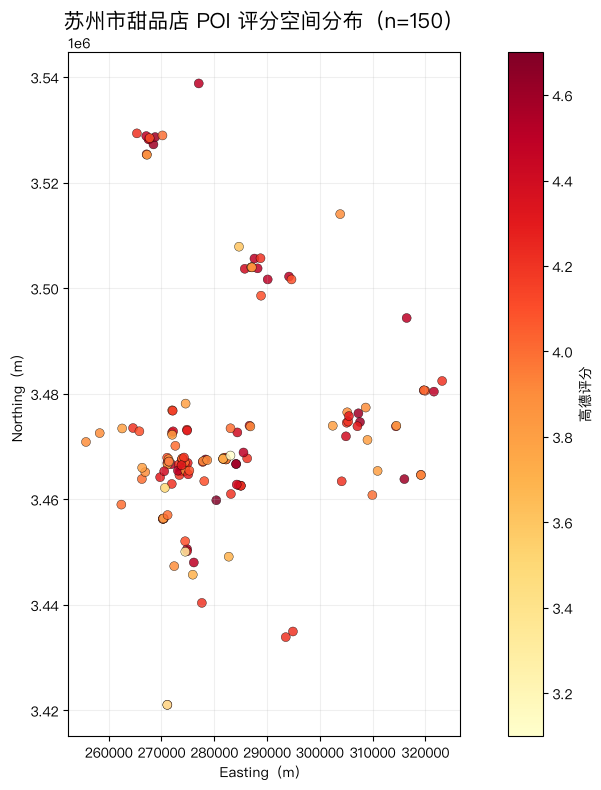

In [21]:
fig, ax = plt.subplots(figsize=(10, 8))

poi_utm.plot(
    ax=ax,
    column="rating",
    cmap="YlOrRd",
    legend=True,
    markersize=42,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.3,
    missing_kwds={"color": "lightgray", "label": "无评分"},
    legend_kwds={"label": "高德评分"},
)

ax.set_title(f"苏州市甜品店 POI 评分空间分布（n={len(poi_utm)}）", fontsize=15)
ax.set_xlabel("Easting（m）")
ax.set_ylabel("Northing（m）")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(figure_dir / "dessert_shop_map.png", dpi=300, bbox_inches="tight")
plt.show()

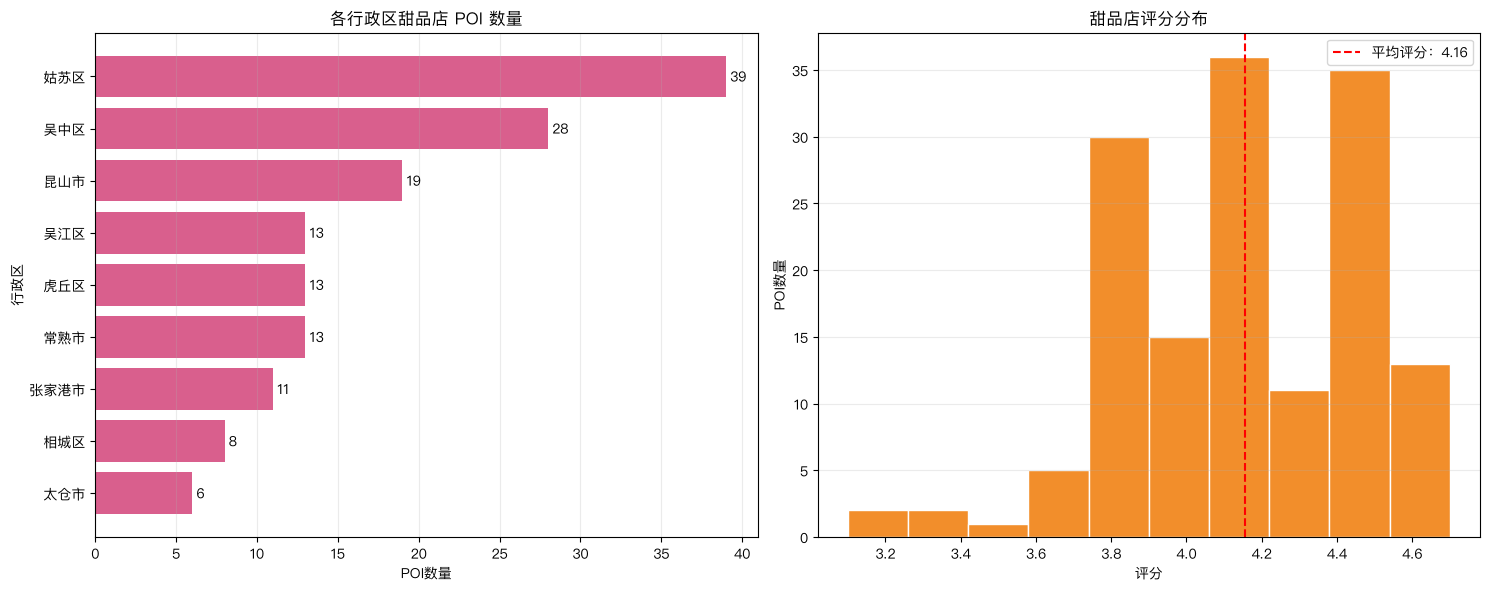

甜品店总数： 150
有效评分数： 150
平均评分： 4.16


In [22]:
district_counts = poi_df["district"].fillna("未知行政区").value_counts().sort_values()
rated_pois = poi_df.dropna(subset=["rating"]).copy()
mean_rating = rated_pois["rating"].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

bars = axes[0].barh(district_counts.index, district_counts.values, color="#d95f8d")
axes[0].bar_label(bars, padding=3)
axes[0].set_title("各行政区甜品店 POI 数量")
axes[0].set_xlabel("POI数量")
axes[0].set_ylabel("行政区")
axes[0].grid(axis="x", alpha=0.25)

axes[1].hist(rated_pois["rating"], bins=10, color="#f28e2b", edgecolor="white")
if pd.notna(mean_rating):
    axes[1].axvline(mean_rating, color="red", linestyle="--", label=f"平均评分：{mean_rating:.2f}")
    axes[1].legend()
axes[1].set_title("甜品店评分分布")
axes[1].set_xlabel("评分")
axes[1].set_ylabel("POI数量")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(figure_dir / "dessert_shop_statistics.png", dpi=300, bbox_inches="tight")
plt.show()

print("甜品店总数：", len(poi_df))
print("有效评分数：", len(rated_pois))
print("平均评分：", round(mean_rating, 2) if pd.notna(mean_rating) else "无有效评分")

In [23]:
interactive_map = poi_wgs84.explore(
    column="rating",
    tooltip=["name", "district", "rating", "cost"],
    popup=["name", "address", "type", "rating", "cost"],
    cmap="YlOrRd",
    tiles="OpenStreetMap",
    marker_kwds={"radius": 6, "fill": True},
    missing_kwds={"color": "lightgray", "label": "无评分"},
    legend=True,
)

interactive_map.save(figure_dir / "dessert_shop_interactive_map.html")
interactive_map

In [24]:
poi_df.to_csv(data_dir / "suzhou_dessert_shops.csv", index=False, encoding="utf-8-sig")
poi_wgs84.to_file(data_dir / "suzhou_dessert_shops.geojson", driver="GeoJSON")
poi_utm.to_file(data_dir / "suzhou_dessert_shops_utm.gpkg", driver="GPKG")

outputs = [
    data_dir / "suzhou_dessert_shops.csv",
    data_dir / "suzhou_dessert_shops.geojson",
    data_dir / "suzhou_dessert_shops_utm.gpkg",
    figure_dir / "dessert_shop_map.png",
    figure_dir / "dessert_shop_statistics.png",
    figure_dir / "dessert_shop_interactive_map.html",
]

summary = pd.DataFrame({
    "文件": [path.as_posix() for path in outputs],
    "大小_KB": [path.stat().st_size / 1024 for path in outputs],
})

summary.style.format({"大小_KB": "{:,.1f}"})

,文件,大小_KB
0,data/suzhou_dessert_shops.csv,32.6
1,data/suzhou_dessert_shops.geojson,71.8
2,data/suzhou_dessert_shops_utm.gpkg,140.0
3,figures/dessert_shop_map.png,215.0
4,figures/dessert_shop_statistics.png,161.8
5,figures/dessert_shop_interactive_map.html,144.4
